# QuantumNet - Standalone final notebook (data setup + feature extraction + hybrid vs classical + ablation)
Before running: right panel > Add Input = APTOS 2019 Blindness Detection, Settings > Accelerator = GPU, Internet = On.
Run cells top to bottom. This notebook does NOT depend on your older notebook.

## Step 1: GPU check

In [1]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## Step 2: Find dataset files automatically

In [2]:
import os, glob
csv_files = glob.glob('/kaggle/input/**/train.csv', recursive=True)
print(csv_files)
CSV_PATH = csv_files[0]
BASE = os.path.dirname(CSV_PATH)
IMG_DIR = os.path.join(BASE, 'train_images')
print(CSV_PATH); print(IMG_DIR, os.path.exists(IMG_DIR))

['/kaggle/input/competitions/aptos2019-blindness-detection/train.csv']
/kaggle/input/competitions/aptos2019-blindness-detection/train.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train_images True


## Step 3: Binary labels + 70/15/15 split (seed 42)

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
SEED = 42
df = pd.read_csv(CSV_PATH)
print(df['diagnosis'].value_counts().sort_index())
df['label'] = (df['diagnosis'] > 0).astype(int)
print(df['label'].value_counts())
ext = os.listdir(IMG_DIR)[0].split('.')[-1]
df['path'] = IMG_DIR + '/' + df['id_code'] + '.' + ext
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))   # expect 2563 549 550
os.makedirs('/kaggle/working', exist_ok=True)
for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    d.to_csv(f'/kaggle/working/{name}_split.csv', index=False)

diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64
label
1    1857
0    1805
Name: count, dtype: int64
2563 549 550


## Step 4: Dataset + augmentation

In [4]:
import numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
torch.manual_seed(SEED); np.random.seed(SEED)
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(20),
    transforms.RandomAffine(0, translate=(0.1, 0.1), shear=10, scale=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])

class DRDataset(Dataset):
    def __init__(self, frame, tf):
        self.paths = frame['path'].tolist(); self.labels = frame['label'].tolist(); self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.tf(img), self.labels[i]

BS = 32
train_loader = DataLoader(DRDataset(train_df, train_tf), batch_size=BS, shuffle=True, num_workers=2)
val_loader   = DataLoader(DRDataset(val_df, eval_tf), batch_size=BS, num_workers=2)
test_loader  = DataLoader(DRDataset(test_df, eval_tf), batch_size=BS, num_workers=2)
x, y = next(iter(train_loader)); print(x.shape, y[:8])

torch.Size([32, 3, 224, 224]) tensor([1, 0, 1, 1, 1, 1, 0, 0])


## Feature extraction: ResNet50 2048-D features (needs the GPU, takes a few minutes)

In [5]:
import torch.nn as nn, torchvision.models as models
resnet_fe = models.resnet50(weights='IMAGENET1K_V2')
resnet_fe.fc = nn.Identity()
resnet_fe = resnet_fe.to(device).eval()

def extract(loader):
    feats, labs = [], []
    with torch.no_grad():
        for x, y in loader:
            feats.append(resnet_fe(x.to(device)).cpu().numpy()); labs += y.tolist()
    return np.concatenate(feats), np.array(labs)

tr_loader_noaug = DataLoader(DRDataset(train_df, eval_tf), batch_size=BS, num_workers=2)
Xtr, ytr = extract(tr_loader_noaug)
Xva, yva = extract(val_loader)
Xte, yte = extract(test_loader)
print(Xtr.shape, Xva.shape, Xte.shape)      # expect (2563, 2048) (549, 2048) (550, 2048)
np.savez('/kaggle/working/resnet50_features.npz', Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 224MB/s]


(2563, 2048) (549, 2048) (550, 2048)


## Cell 1: install + imports

In [6]:
!pip -q install pennylane
import numpy as np, torch, torch.nn as nn, time, json
import pennylane as qml
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt
print('torch', torch.__version__, '| pennylane', qml.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 64.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 48.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 77.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 81.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 111.7 MB/s eta 0:00:00
torch 2.11.0+cu128 | pennylane 0.45.1


## Cell 2: load cached features

In [7]:
FEATS = '/kaggle/working/resnet50_features.npz'   # change path if you saved it elsewhere
d = np.load(FEATS)
Xtr, ytr, Xva, yva, Xte, yte = [d[k] for k in ('Xtr','ytr','Xva','yva','Xte','yte')]
print(Xtr.shape, Xva.shape, Xte.shape)          # expect (2563,2048) (549,2048) (550,2048)
sc = StandardScaler().fit(Xtr)
T = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr_t, Xva_t, Xte_t = T(sc.transform(Xtr)), T(sc.transform(Xva)), T(sc.transform(Xte))
ytr_t, yva_t, yte_t = [torch.tensor(a, dtype=torch.long) for a in (ytr, yva, yte)]
crit = nn.CrossEntropyLoss()

(2563, 2048) (549, 2048) (550, 2048)


## Cell 3: models (paper-style dressed quantum circuit, generalised to n qubits / n layers)

In [8]:
def make_circuit(n_qubits, n_layers):
    dev = qml.device('default.qubit', wires=n_qubits)
    @qml.qnode(dev, interface='torch', diff_method='backprop')
    def circ(inputs, weights):
        for i in range(n_qubits):
            qml.Hadamard(wires=i)
        for i in range(n_qubits):
            qml.RY(inputs[..., i], wires=i)
        for l in range(n_layers):
            for i in range(0, n_qubits - 1, 2): qml.CNOT(wires=[i, i + 1])
            for i in range(1, n_qubits - 1, 2): qml.CNOT(wires=[i, i + 1])
            for i in range(n_qubits):
                qml.RY(weights[l, i], wires=i)
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]
    return circ

def small_init(t): return nn.init.normal_(t, mean=0.0, std=0.01)

class QHead(nn.Module):
    def __init__(self, n_qubits=4, n_layers=6):
        super().__init__()
        self.pre = nn.Sequential(nn.Linear(2048, n_qubits), nn.Tanh())
        self.q = qml.qnn.TorchLayer(make_circuit(n_qubits, n_layers), {'weights': (n_layers, n_qubits)}, init_method=small_init)
        self.out = nn.Linear(n_qubits, 2)
    def forward(self, x):
        return self.out(self.q(self.pre(x) * np.pi / 2))

class CHead(nn.Module):
    def __init__(self, n_qubits=4):
        super().__init__()
        self.pre = nn.Sequential(nn.Linear(2048, n_qubits), nn.Tanh())
        self.mid = nn.Sequential(nn.Linear(n_qubits, n_qubits), nn.Tanh())
        self.out = nn.Linear(n_qubits, 2)
    def forward(self, x):
        return self.out(self.mid(self.pre(x)))

def run_model(make_model, seed, lr_pre=3e-4, lr_other=3e-3, wd=1e-3, epochs=40, patience=8):
    torch.manual_seed(seed); np.random.seed(seed)
    m = make_model()
    other = [p for n, p in m.named_parameters() if not n.startswith('pre.')]
    opt = torch.optim.Adam([{'params': m.pre.parameters(), 'lr': lr_pre, 'weight_decay': wd},
                            {'params': other, 'lr': lr_other}])
    best_va, best_state, bad = 0, None, 0
    for ep in range(epochs):
        m.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(perm), 64):
            idx = perm[i:i + 64]
            opt.zero_grad(); crit(m(Xtr_t[idx]), ytr_t[idx]).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            va = (m(Xva_t).argmax(1) == yva_t).float().mean().item()
        if va > best_va:
            best_va, bad = va, 0
            best_state = {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(best_state); m.eval()
    with torch.no_grad():
        pred = m(Xte_t).argmax(1).numpy()
    return best_va, float((pred == yte).mean()), pred

## Cell 4: timing test (run this first, it takes only a moment)

In [9]:
t0 = time.time()
va, te, _ = run_model(lambda: QHead(4, 6), seed=0)
print(f'one hybrid run (4 qubits, 6 layers): val {va:.4f} test {te:.4f} in {time.time()-t0:.0f}s')
print('6 qubits x 6 layers will be slower; multiply the time above by about 3-4 as a rough guess')

one hybrid run (4 qubits, 6 layers): val 0.9763 test 0.9545 in 37s
6 qubits x 6 layers will be slower; multiply the time above by about 3-4 as a rough guess


## Cell 5: main comparison, hybrid vs classical, 6 seeds (with per-class metrics)

In [10]:
SEEDS = [0, 1, 2, 3, 4, 5]
main = {'hybrid': [], 'classical': []}
for s in SEEDS:
    main['hybrid'].append(run_model(lambda: QHead(4, 6), s))
    main['classical'].append(run_model(lambda: CHead(4), s))
    print(f'seed {s}: hybrid test {main["hybrid"][-1][1]:.4f} | classical test {main["classical"][-1][1]:.4f}')

acc = {k: np.array([r[1] for r in v]) for k, v in main.items()}
for k in acc: print(f'{k}: mean {acc[k].mean():.4f} +/- {acc[k].std():.4f}')
print('Wilcoxon (hybrid vs classical):', wilcoxon(acc['hybrid'], acc['classical']))

for k in main:
    print('\n===', k, '(seed 0) ===')
    p = main[k][0][2]
    print(classification_report(yte, p, target_names=['No DR', 'DR'], digits=4))
    print(confusion_matrix(yte, p))

seed 0: hybrid test 0.9545 | classical test 0.9509
seed 1: hybrid test 0.9436 | classical test 0.9509
seed 2: hybrid test 0.9491 | classical test 0.9527
seed 3: hybrid test 0.9491 | classical test 0.9545
seed 4: hybrid test 0.9545 | classical test 0.9473
seed 5: hybrid test 0.9473 | classical test 0.9582
hybrid: mean 0.9497 +/- 0.0039
classical: mean 0.9524 +/- 0.0034
Wilcoxon (hybrid vs classical): WilcoxonResult(statistic=np.float64(6.0), pvalue=np.float64(0.46875))

=== hybrid (seed 0) ===
              precision    recall  f1-score   support

       No DR     0.9556    0.9520    0.9538       271
          DR     0.9536    0.9570    0.9553       279

    accuracy                         0.9545       550
   macro avg     0.9546    0.9545    0.9545       550
weighted avg     0.9545    0.9545    0.9545       550

[[258  13]
 [ 12 267]]

=== classical (seed 0) ===
              precision    recall  f1-score   support

       No DR     0.9656    0.9336    0.9493       271
          DR   

## Cell 6: ablation, qubits x layers (3 seeds each). If this is too slow, shrink ABL_SEEDS to [0].

In [11]:
ABL_SEEDS = [0, 1, 2]
QUBITS, LAYERS = [2, 4, 6], [1, 3, 6]
abl = {}
for nq in QUBITS:
    for nl in LAYERS:
        t0 = time.time()
        accs = [run_model(lambda: QHead(nq, nl), s)[1] for s in ABL_SEEDS]
        abl[(nq, nl)] = accs
        print(f'qubits={nq} layers={nl}: mean {np.mean(accs):.4f} +/- {np.std(accs):.4f}  ({time.time()-t0:.0f}s)')

qubits=2 layers=1: mean 0.9127 +/- 0.0239  (17s)
qubits=2 layers=3: mean 0.9388 +/- 0.0199  (24s)
qubits=2 layers=6: mean 0.9497 +/- 0.0023  (22s)
qubits=4 layers=1: mean 0.9491 +/- 0.0030  (28s)
qubits=4 layers=3: mean 0.9418 +/- 0.0077  (37s)
qubits=4 layers=6: mean 0.9491 +/- 0.0045  (70s)
qubits=6 layers=1: mean 0.9479 +/- 0.0034  (40s)
qubits=6 layers=3: mean 0.9448 +/- 0.0052  (50s)
qubits=6 layers=6: mean 0.9485 +/- 0.0023  (75s)


## Cell 7: tables and plots for the report + save everything

| Qubits | Layers | Test acc (mean +/- std, 3 seeds) |
| --- | --- | --- |
| 2 | 1 | 91.27 +/- 2.39 |
| 2 | 3 | 93.88 +/- 1.99 |
| 2 | 6 | 94.97 +/- 0.23 |
| 4 | 1 | 94.91 +/- 0.30 |
| 4 | 3 | 94.18 +/- 0.77 |
| 4 | 6 | 94.91 +/- 0.45 |
| 6 | 1 | 94.79 +/- 0.34 |
| 6 | 3 | 94.48 +/- 0.52 |
| 6 | 6 | 94.85 +/- 0.23 |


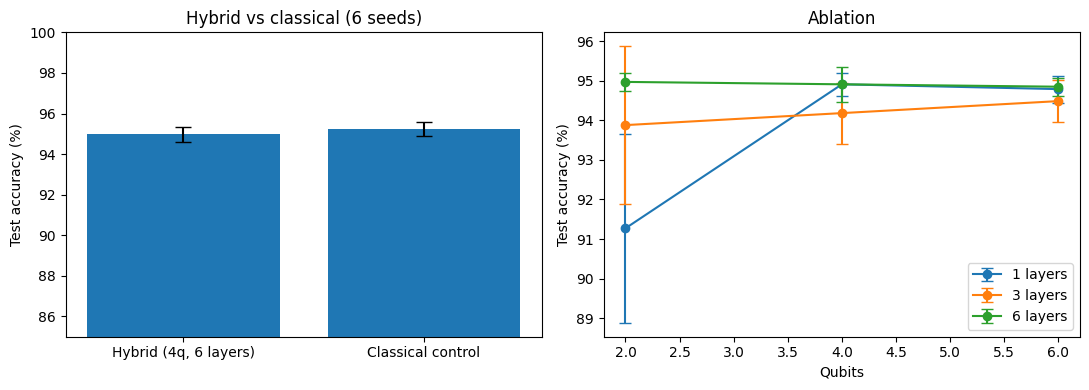

saved part2_results.json and part2_results.png in /kaggle/working


In [12]:
print('| Qubits | Layers | Test acc (mean +/- std, %d seeds) |' % len(ABL_SEEDS))
print('| --- | --- | --- |')
for (nq, nl), a in abl.items():
    print(f'| {nq} | {nl} | {np.mean(a)*100:.2f} +/- {np.std(a)*100:.2f} |')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
labels = ['Hybrid (4q, 6 layers)', 'Classical control']
ax[0].bar(labels, [acc['hybrid'].mean()*100, acc['classical'].mean()*100],
          yerr=[acc['hybrid'].std()*100, acc['classical'].std()*100], capsize=6)
ax[0].set_ylim(85, 100); ax[0].set_ylabel('Test accuracy (%)'); ax[0].set_title('Hybrid vs classical (6 seeds)')
for nl in LAYERS:
    ax[1].errorbar(QUBITS, [np.mean(abl[(nq, nl)])*100 for nq in QUBITS],
                   yerr=[np.std(abl[(nq, nl)])*100 for nq in QUBITS], marker='o', capsize=4, label=f'{nl} layers')
ax[1].set_xlabel('Qubits'); ax[1].set_ylabel('Test accuracy (%)'); ax[1].set_title('Ablation'); ax[1].legend()
plt.tight_layout(); plt.savefig('/kaggle/working/part2_results.png', dpi=150); plt.show()

json.dump({'main_hybrid': acc['hybrid'].tolist(), 'main_classical': acc['classical'].tolist(),
           'ablation': {f'{k[0]}q_{k[1]}l': v for k, v in abl.items()}},
          open('/kaggle/working/part2_results.json', 'w'), indent=2)
print('saved part2_results.json and part2_results.png in /kaggle/working')

## After this: Save Version > Save & Run All, then send me the printed outputs of Cells 4, 5, 6 and 7.